# History of all rounds

The pipeline was run in four rounds that differ in the selection rule and the epoch cap. The c-notebooks show
the reported round (r2). This notebook compares all four: what was tried, what it scored, and which decision it
led to. Nothing is recomputed; it reads the stored run records from `results/` (r2) and `history/rounds/`
(r0, r1, r3). The reasons behind each round are in `history/README.md`.

| Round | Device | Selection rule | Epoch cap | Steps |
|---|---|---|---|---|
| r0 | Apple M1 (MPS) | tie rule: change only if better by > 2·σ_seed·√(2/n) ≈ 5 pp, else keep the simpler/default option | 60 | c1 to c5; c6 and c7 partly |
| r1 | RTX 2080 Ti (CUDA) | tie rule (as r0) | 60 | c6 to c10 |
| r2 (reported) | RTX 2080 Ti (CUDA) | highest mean val balanced accuracy wins | 60 | c5 to c10 |
| r3 | RTX 2080 Ti (CUDA) | highest mean val balanced accuracy wins | 200 (early stopping, patience 20) | c5 to c10 |

Every number is val balanced accuracy on clean val (832 images), mean over seeds unless stated. No round used the
test set; the final models were evaluated on it once, afterwards (`test_evaluation.ipynb`).

In [1]:
import json, re
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import Markdown, display
pd.set_option("display.max_rows", 500, "display.max_colwidth", 80, "display.width", 200)

H = Path("../history/rounds")
ROUNDS = {   # round -> (results dir, artifacts dir)
    "r0": (H / "r0/results", H / "r0/artifacts"),
    "r1": (H / "r1/results", None),
    "r2": (Path("../results"), Path("../artifacts")),
    "r3": (H / "r3/results", H / "r3/artifacts"),
}

rows = []
for rnd, (rdir, _) in ROUNDS.items():
    for f in sorted(rdir.glob("c*/*.json")):
        r = json.loads(f.read_text()); c = r["config"]; v = r["val"]
        rows.append({"round": rnd, "exp": f.parent.name, "option": re.sub(r"_s\d{4}$", "", c["name"]), "seed": c["seed"],
                     "bal_acc": v["bal_acc"], "macro_f1": v["macro_f1"], "tumor_auc": v["tumor_auc"],
                     "best_ep": r["best_epoch"], "epochs_run": r["epochs_run"], "cap": c["epochs"],
                     "params": r["n_params"], "device": r.get("device", "?")})
runs = pd.DataFrame(rows)
# A round's results folder also holds files from earlier rounds (reused from the cache, or never revisited).
# Identical records are the same training run: keep it once, under the round that trained it.
runs["key"] = runs[["exp", "option", "seed", "bal_acc", "epochs_run"]].astype(str).agg("|".join, axis=1)
runs = runs.drop_duplicates("key", keep="first").drop(columns="key")
print(f"{len(runs)} distinct training runs, by the round that trained them:", runs.groupby("round").size().to_dict())

534 distinct training runs, by the round that trained them: {'r0': 125, 'r1': 75, 'r2': 155, 'r3': 179}


## 1. Decisions per round

What each round decided at each step. r1 kept no decision files; its decisions are filled in from
`history/README.md`.

In [2]:
def load(art, name):
    p = art / name if art else None
    return json.loads(p.read_text()) if p and p.exists() else {}

def arch_str(a):
    if not a: return None
    return (f"{'residual' if a['residual'] else 'plain'} {1 + 4 * a['depths'][0] if a['block'] == 'single' else 1 + 8 * a['depths'][0]} layers, "
            f"{a['kernel']}x{a['kernel']}, {a['downsample']}, width {a['widths'][0]}")

def final_score(rdir, art):
    name = load(art, "final.json").get("config", {}).get("name", "final_s1738")   # r3 moved to final_lr0.01
    f = rdir / "c9" / f"{name}.json"
    return round(json.loads(f.read_text())["val"]["bal_acc"], 4) if f.exists() else None

dec = {}
for rnd, (rdir, art) in ROUNDS.items():
    i, o, a, g, t = (load(art, n) for n in ["input.json", "optim.json", "arch.json", "reg.json", "threshold.json"])
    dec[rnd] = {"input": i and f"{i['mode']}, {i['resize']}, {i['size']} px, {i['normalize']} norm",
                "optimiser / lr": o and f"{o['optimizer']} {o['lr']:g}", "batch size": o.get("batch_size"),
                "lr schedule": o.get("schedule"), "loss": o.get("loss"),
                "small candidate": arch_str(a.get("small")), "deep candidate": arch_str(a.get("deep")),
                "winner": g.get("winner"), "augmentation": g.get("aug"), "weight decay": g.get("weight_decay"),
                "dropout": g.get("dropout"), "final model val bal. acc (seed 1738)": final_score(rdir, art),
                "tumour threshold": (round(t["threshold"], 3) if t.get("threshold") is not None else "argmax") if t else None}
dec["r1"] = {"input": "gray, crop, 128 px, global norm", "optimiser / lr": "adam 0.03", "batch size": 32,
             "lr schedule": "none", "loss": "ce", "small candidate": "plain 5 layers, 3x3, maxpool, width 16",
             "deep candidate": "residual 17 layers, 3x3, maxpool, width 16", "winner": "small", "augmentation": "none",
             "weight decay": 0.0, "dropout": 0.0, "final model val bal. acc (seed 1738)": 0.932, "tumour threshold": 0.405}
dec["r0"]["optimiser / lr"] = dec["r0"]["optimiser / lr"] + " (c4 default; r0 ended during c6)"
D = pd.DataFrame(dec)[list(ROUNDS)].replace({"": None})
display(D)

,r0,r1,r2,r3
input,"gray, crop, 128 px, global norm","gray, crop, 128 px, global norm","gray, crop, 128 px, per_image norm","gray, crop, 128 px, per_image norm"
optimiser / lr,adam 0.001 (c4 default; r0 ended during c6),adam 0.03,adam 0.03,adam 0.03
batch size,64,32,64,128
lr schedule,none,none,none,none
loss,ce,ce,label_smoothing,focal
small candidate,None,"plain 5 layers, 3x3, maxpool, width 16","plain 5 layers, 5x5, avgpool, width 16","residual 9 layers, 5x5, avgpool, width 16"
deep candidate,None,"residual 17 layers, 3x3, maxpool, width 16","residual 17 layers, 5x5, avgpool, width 32","residual 17 layers, 5x5, avgpool, width 16"
winner,None,small,small,small
augmentation,None,none,mild,geometric
weight decay,None,0.0,0.0,0.0


## 2. Final model score per round

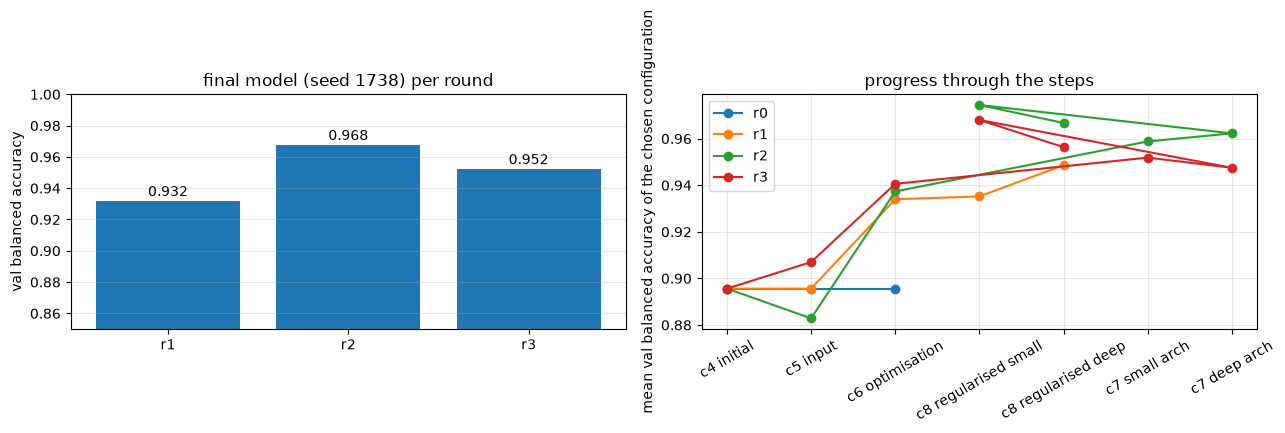

In [3]:
prog = {rnd: load(art, "progress.json") for rnd, (_, art) in ROUNDS.items()}
prog["r1"] = {"c4 initial": 0.8956, "c5 input": 0.8956, "c6 optimisation": 0.934, "c8 regularised small": 0.9352,
              "c8 regularised deep": 0.9486}
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
fs = {r: D.loc["final model val bal. acc (seed 1738)", r] for r in ROUNDS}
fs = {r: v for r, v in fs.items() if v is not None and not pd.isna(v)}
ax[0].bar(list(fs), list(fs.values()), color="C0"); ax[0].set(ylim=(0.85, 1), ylabel="val balanced accuracy",
          title="final model (seed 1738) per round"); ax[0].grid(alpha=0.3, axis="y")
for k, v in fs.items(): ax[0].text(k, v + 0.003, f"{v:.3f}", ha="center")
for rnd, p in prog.items():
    if p: ax[1].plot(list(p), list(p.values()), "o-", label=rnd)
ax[1].set(ylabel="mean val balanced accuracy of the chosen configuration", title="progress through the steps")
ax[1].tick_params(axis="x", rotation=30); ax[1].grid(alpha=0.3); ax[1].legend()
plt.tight_layout(); plt.show()

## 3. Every configuration tried, per notebook

One row per configuration (run name without the seed), one column block per round: mean val balanced accuracy,
number of seeds, and the mean number of epochs actually trained. Each run is listed under the round that trained
it; a later round that reused it from the cache shows an empty cell. Run names encode the choices made earlier in
the same round, so the same question can appear under different names in different rounds (for example
`k3s3_maxpool_plain17` in r1 and `k5s5_avgpool_plain17` in r2).

In [4]:
agg = (runs.groupby(["exp", "option", "round"])
           .agg(bal_acc=("bal_acc", "mean"), sd=("bal_acc", "std"), n=("seed", "size"), epochs=("epochs_run", "mean"))
           .round(4).reset_index())
for exp in sorted(agg.exp.unique()):
    t = agg[agg.exp == exp].pivot(index="option", columns="round", values=["bal_acc", "n", "epochs"])
    t = t.swaplevel(axis=1).sort_index(axis=1, level=0)
    display(Markdown(f"### {exp}"))
    display(t.astype(object).where(t.notna(), ""))

### c4

round          r0            
          bal_acc epochs    n
option                       
long       0.8817   60.0  5.0
overfit64  0.6104  150.0  1.0
seed       0.8892   54.4  5.0

### c5

round              r0                    r2                  r3              
              bal_acc   epochs    n bal_acc epochs    n bal_acc   epochs    n
option                                                                       
crop                                                     0.8949     75.0  3.0
input_choice                         0.8828   47.0  3.0   0.907  62.3333  3.0
pad            0.9031     49.0  3.0                      0.9118     81.0  3.0
perimage       0.9006     51.0  3.0                      0.9038  52.3333  3.0
probe_crop     0.7381  44.3333  3.0                      0.7461  40.3333  3.0
probe_pad      0.7872  48.3333  3.0                       0.805  44.6667  3.0
probe_stretch  0.7968  40.3333  3.0                      0.7927  43.6667  3.0
r192           0.8457  42.3333  3.0                      0.8798  47.6667  3.0
r64            0.8855     48.0  3.0                      0.8917     57.0  3.0
rgb            0.8772     50.0  3.0                       0.887     52.0  3.0
stretch        0.8818  39.6667  3.0                      0.8815     44.0  3.0

### c6

round                               r0                    r1                    r2                    r3              
                               bal_acc   epochs    n bal_acc   epochs    n bal_acc   epochs    n bal_acc   epochs    n
option                                                                                                                
adam_lr0.0001                   0.8557     60.0  3.0                        0.8778     60.0  3.0  0.8833  83.6667  3.0
adam_lr0.0003                   0.8716  55.3333  3.0                         0.892  48.3333  3.0  0.8909  72.3333  3.0
adam_lr0.001_bs128              0.8912     60.0  3.0                                                                  
adam_lr0.001_bs32               0.8674  43.3333  3.0                                                                  
adam_lr0.001_bs64_cosine        0.8998     56.0  3.0                                                                  
adam_lr0.001_bs64_none_focal     0.895  56.6667  3.0                                                                  
adam_lr0.001_bs64_none_ls        0.882     48.0  3.0                                                                  
adam_lr0.001_bs64_none_sampler  0.8741  48.6667  3.0                                                                  
adam_lr0.001_bs64_none_wce      0.9034     60.0  3.0                                                                  
adam_lr0.001_bs64_plateau       0.8911     52.0  3.0                                                                  
adam_lr0.001_bs64_step           0.898  57.3333  3.0                                                                  
adam_lr0.003                    0.9133  56.6667  3.0                        0.9112  45.6667  3.0  0.8898  58.3333  3.0
adam_lr0.01                     0.9218     59.0  3.0                        0.9209  54.6667  3.0  0.9137  52.3333  3.0
adam_lr0.03                     0.9275     60.0  3.0                        0.9371     55.0  3.0  0.9359  64.3333  3.0
adam_lr0.03_bs128               0.9162     59.0  3.0                        0.9223  50.6667  3.0  0.9381     68.0  3.0
adam_lr0.03_bs128_cosine                                                                          0.9133  55.3333  3.0
adam_lr0.03_bs128_none_focal                                                                      0.9406  77.3333  3.0
adam_lr0.03_bs128_none_ls                                                                         0.9309  51.6667  3.0
adam_lr0.03_bs128_none_sampler                                                                    0.9347     70.0  3.0
adam_lr0.03_bs128_none_wce                                                                        0.9368  87.3333  3.0
adam_lr0.03_bs128_plateau                                                                         0.9324     46.0  3.0
adam_lr0.03_bs128_step                                                                            0.9292  62.6667  3.0
adam_lr0.03_bs32                 0.934     60.0  3.0                        0.9305     58.0  3.0   0.935     71.0  3.0
adam_lr0.03_bs32_cosine         0.9316  59.6667  3.0                                                                  
adam_lr0.03_bs32_none_focal                           0.9221     60.0  3.0                                            
adam_lr0.03_bs32_none_ls                              0.9369  50.6667  3.0                                            
adam_lr0.03_bs32_none_sampler                         0.9235     60.0  3.0                                            
adam_lr0.03_bs32_none_wce                              0.934  55.6667  3.0                                            
adam_lr0.03_bs32_plateau                              0.9319     45.0  3.0                                            
adam_lr0.03_bs32_step                                 0.9389     60.0  3.0                                            
adam_lr0.03_bs64_cosine                                                  

... (2 outputs left out)

### c8

round                              r1                    r2                    r3              
                              bal_acc   epochs    n bal_acc   epochs    n bal_acc   epochs    n
option                                                                                         
deep_aug_geometric                                   0.9611     60.0  2.0   0.933     49.0  2.0
deep_aug_geometric_wd0.01                            0.9504     55.5  2.0                      
deep_aug_geometric_wd0.1                             0.8584     39.0  2.0                      
deep_aug_geometric_wd0_do0.3                         0.9667     60.0  2.0                      
deep_aug_mild                                         0.961     54.0  2.0  0.9534     72.5  2.0
deep_aug_none                                        0.9602     58.5  2.0  0.9564     86.5  2.0
deep_aug_none_wd0.01           0.9343     60.0  2.0                        0.9535     74.5  2.0
deep_aug_none_wd0.1            0.7825     30.5  2.0                        0.8677     54.0  2.0
deep_aug_none_wd0_do0.3        0.9532     52.0  2.0                        0.9442     87.5  2.0
deep_aug_strong                                      0.9585     60.0  2.0  0.9463     64.5  2.0
small_aug_geometric                                   0.968     60.0  3.0   0.968  76.6667  3.0
small_aug_geometric_wd0.01                                                 0.9524  76.3333  3.0
small_aug_geometric_wd0.1                                                  0.8786  50.6667  3.0
small_aug_geometric_wd0_do0.3                                              0.9591  94.3333  3.0
small_aug_mild                                       0.9744  59.3333  3.0  0.9639     93.0  3.0
small_aug_mild_wd0.01                                0.9525  58.6667  3.0                      
small_aug_mild_wd0.1                                 0.8266  43.3333  3.0                      
small_aug_mild_wd0_do0.3                             0.9632     60.0  3.0                      
small_aug_none                                       0.9572  49.6667  3.0  0.9505     57.0  3.0
small_aug_none_wd0.01          0.8953  52.3333  3.0                                            
small_aug_none_wd0.1           0.7602  33.6667  3.0                                            
small_aug_none_wd0_do0.3       0.9218     55.0  3.0                                            
small_aug_strong                                     0.9591     60.0  3.0  0.9612     90.0  3.0

### c9

round             r2                  r3              
             bal_acc epochs    n bal_acc   epochs    n
option                                                
final         0.9685   60.0  3.0  0.9521  55.3333  3.0
final_lr0.01                      0.9598  73.3333  3.0
lr0.01        0.9649   60.0  3.0  0.9601     81.0  3.0
lr0.09         0.952   60.0  3.0  0.9391  60.3333  3.0

## 4. Every single run

In [5]:
display(runs.sort_values(["round", "exp", "option", "seed"]).reset_index(drop=True).round(4))

,round,exp,option,seed,bal_acc,macro_f1,tumor_auc,best_ep,epochs_run,cap,params,device
0,r0,c4,long,1738,0.8977,0.8965,0.9895,54,60,60,100244,mps
1,r0,c4,long,1739,0.8735,0.8781,0.9912,47,60,60,100244,mps
2,r0,c4,long,1740,0.8663,0.8671,0.9909,31,60,60,100244,mps
3,r0,c4,long,1741,0.8723,0.8764,0.9903,37,60,60,100244,mps
4,r0,c4,long,1742,0.8986,0.8965,0.9950,52,60,60,100244,mps
...,...,...,...,...,...,...,...,...,...,...,...,...
529,r3,c9,lr0.01,1739,0.9662,0.9602,0.9974,96,116,200,832308,cuda
530,r3,c9,lr0.01,1740,0.9560,0.9530,0.9951,52,72,200,832308,cuda
531,r3,c9,lr0.09,1738,0.9475,0.9396,0.9937,59,79,200,832308,cuda
532,r3,c9,lr0.09,1739,0.9388,0.9303,0.9954,26,46,200,832308,cuda
